# Soil Structured-Data Model — XGBoost

Gradient-boosted model on structured soil test parameters (**N, P, K, temperature, humidity, pH, rainfall**).

This notebook complements the ResNet-50 soil-*type* CNN (`notebooks/cnn_soil_type.ipynb`). It delivers the two
structured-data outcomes from the project documentation:

1. **Rule-based NPK/pH deficiency flags** — agronomic thresholds mapped from the raw N/P/K/pH values.
2. **Crop recommendation model** — an XGBoost classifier predicting the best crop (`label`).

> Dataset: `data/crop_recommendation.csv` (Kaggle: Atharva Ingle / Crop Recommendation Dataset — 2,200 rows, 22 crops).

## 1. Install & Import

In [1]:
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb
import joblib

RANDOM_STATE = 42

## 2. Load Dataset

Paths are resolved relative to the repo root so the notebook runs from `notebooks/` locally or from a flat
working dir on Kaggle/Colab.

In [3]:
# Resolve repo root whether run from notebooks/ or repo root
CWD = Path.cwd()
REPO_ROOT = CWD.parent if CWD.name == 'notebooks' else CWD

DATA_PATH = '/kaggle/input/datasets/nukalasasank/xuv123/crop_recommendation.csv'
MODELS_DIR = REPO_ROOT / 'models'
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
df.info()
print()
print('Missing values per column:')
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [5]:
print('Number of crops:', df['label'].nunique())
df['label'].value_counts()

Number of crops: 22


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

## 3. Exploratory Data Analysis

In [6]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


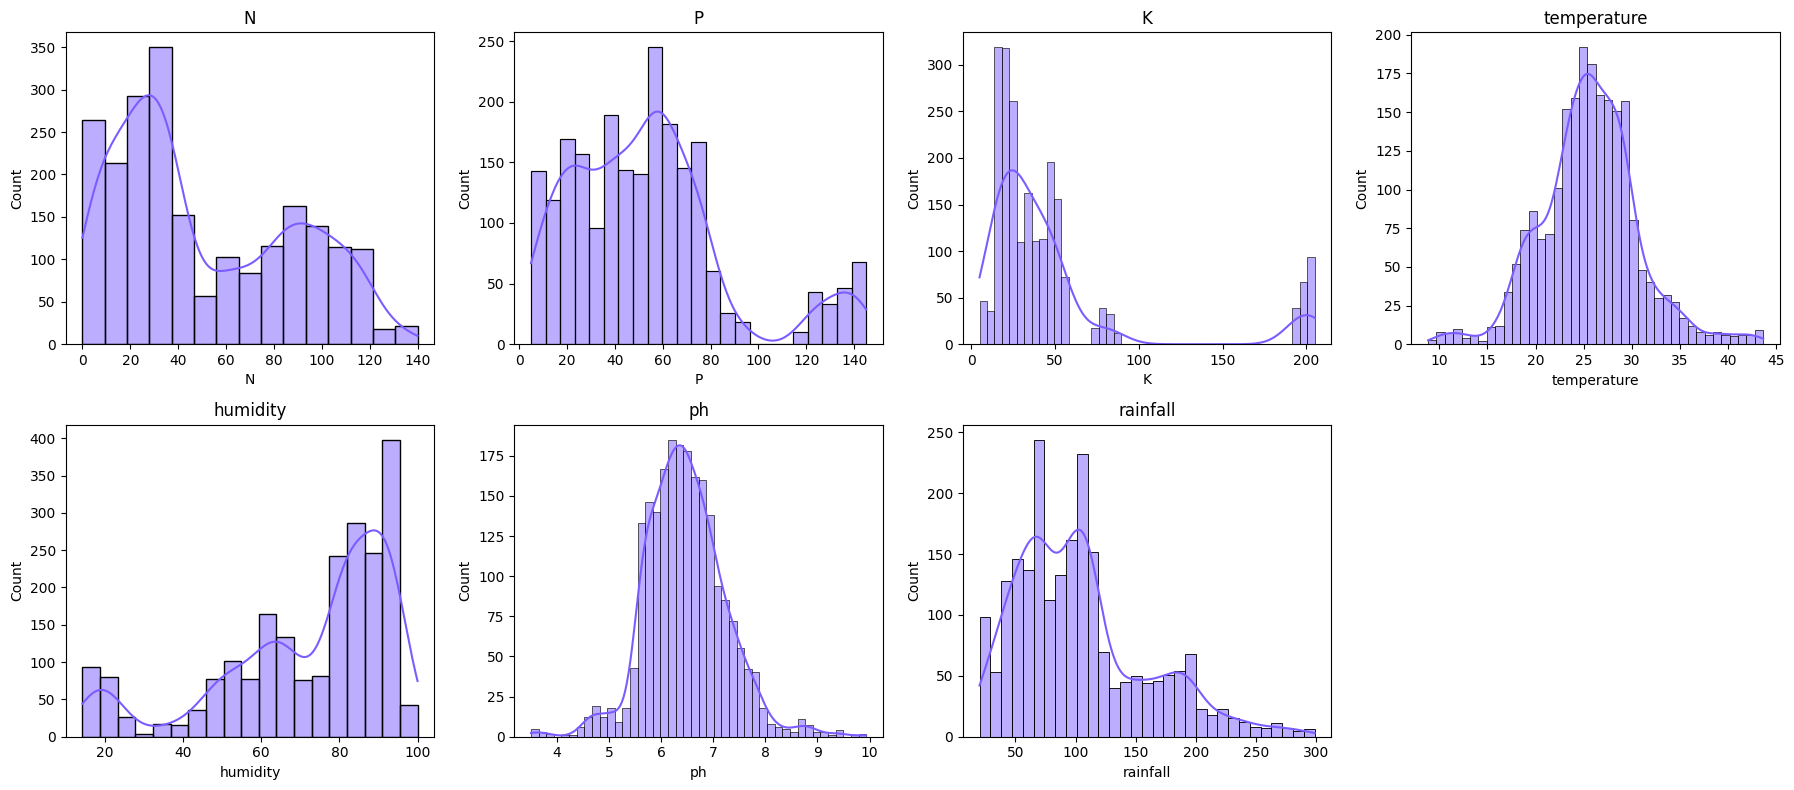

In [7]:
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, feature_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='#7c5cff')
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

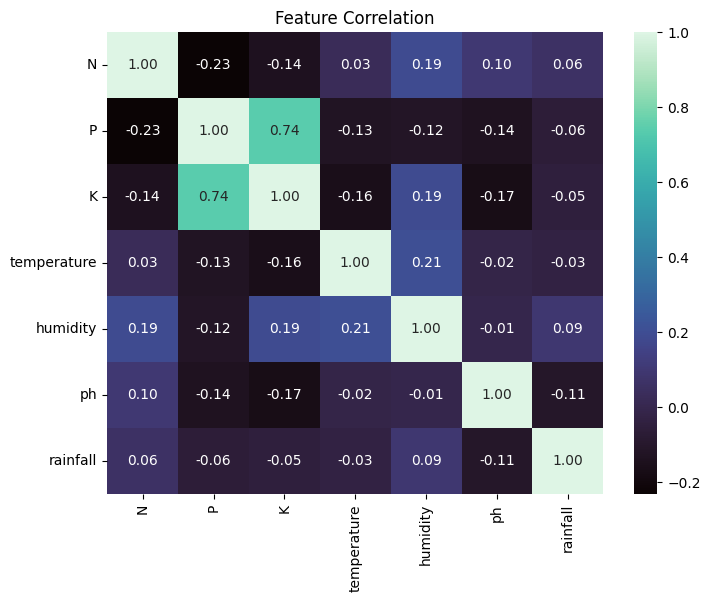

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_cols].corr(), annot=True, fmt='.2f', cmap='mako')
plt.title('Feature Correlation')
plt.show()

## 4. Rule-Based NPK / pH Deficiency Flags

The dataset has no ground-truth deficiency labels, so we derive them from agronomic thresholds.
These flags feed the knowledge-based recommendation engine (fertilizer advisory) and are stored
alongside each record. Thresholds below are typical starting values — tune with an agronomist / ICAR
Soil Health Card reference bands for production use.

In [9]:
# Agronomic threshold bands (adjust per crop/region as needed)
THRESHOLDS = {
    'N':  {'low': 40, 'high': 80},   # nitrogen
    'P':  {'low': 30, 'high': 60},   # phosphorus
    'K':  {'low': 30, 'high': 60},   # potassium
}

def nutrient_status(value, low, high):
    if value < low:
        return 'low'
    if value > high:
        return 'high'
    return 'adequate'

def ph_status(value):
    if value < 6.0:
        return 'acidic'
    if value > 7.5:
        return 'alkaline'
    return 'neutral'

df['N_status'] = df['N'].apply(lambda v: nutrient_status(v, **THRESHOLDS['N']))
df['P_status'] = df['P'].apply(lambda v: nutrient_status(v, **THRESHOLDS['P']))
df['K_status'] = df['K'].apply(lambda v: nutrient_status(v, **THRESHOLDS['K']))
df['pH_status'] = df['ph'].apply(ph_status)

df[['N', 'N_status', 'P', 'P_status', 'K', 'K_status', 'ph', 'pH_status']].head(10)

,N,N_status,P,P_status,K,K_status,ph,pH_status
0,90,high,42,adequate,43,adequate,6.502985,neutral
1,85,high,58,adequate,41,adequate,7.038096,neutral
2,60,adequate,55,adequate,44,adequate,7.840207,alkaline
3,74,adequate,35,adequate,40,adequate,6.980401,neutral
4,78,adequate,42,adequate,42,adequate,7.628473,alkaline
5,69,adequate,37,adequate,42,adequate,7.073454,neutral
6,69,adequate,55,adequate,38,adequate,5.700806,acidic
7,94,high,53,adequate,40,adequate,5.718627,acidic
8,89,high,54,adequate,38,adequate,6.685346,neutral
9,68,adequate,58,adequate,38,adequate,6.336254,neutral


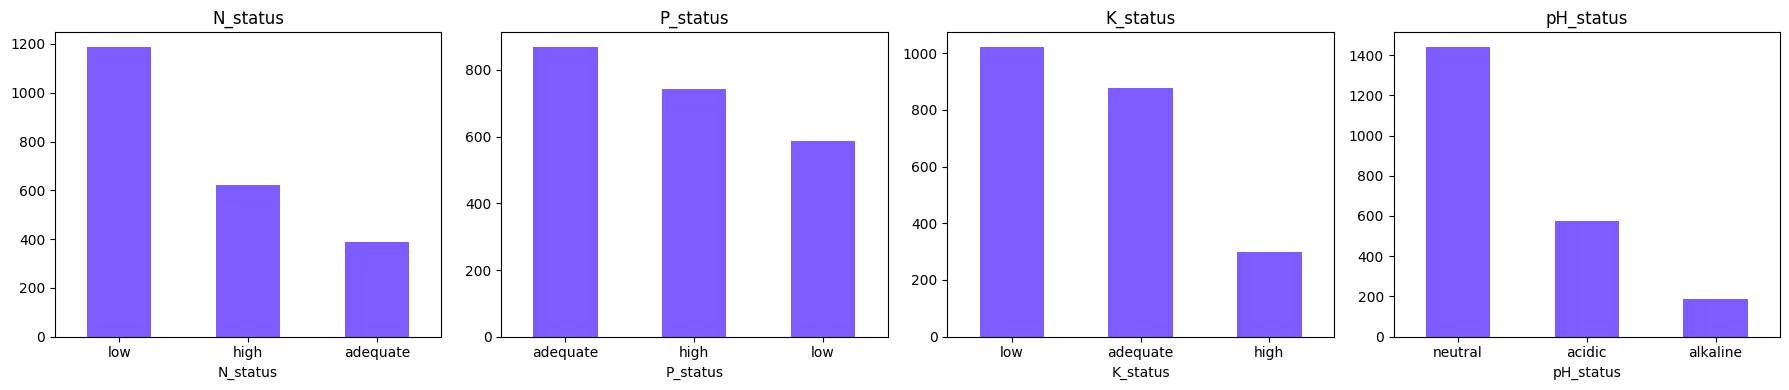

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['N_status', 'P_status', 'K_status', 'pH_status']):
    df[col].value_counts().plot(kind='bar', ax=ax, color='#7c5cff')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 5. Prepare Features & Target for the Crop Model

The crop-recommendation classifier trains on the seven raw numeric features. Target is the crop `label`.

In [11]:
X = df[feature_cols].copy()
y_raw = df['label'].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print('Classes:', list(label_encoder.classes_))
print('Feature matrix:', X.shape)

Classes: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']
Feature matrix: (2200, 7)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1760, 7) | Test: (440, 7)


## 6. Define the XGBoost Model

Multi-class gradient-boosted trees. Hyperparameters are a sensible starting point — run the
training cell in Section 7 when ready (kept separate so this notebook can be reviewed without training).

In [13]:
model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='multi:softprob',
    num_class=len(label_encoder.classes_),
    eval_metric='mlogloss',
    tree_method='hist',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
model

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1, num_class=22, ...)

## 7. Train

**Not run yet.** Execute this cell to fit the model.

In [14]:
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)
print('Training complete.')

Training complete.


## 8. Evaluate

In [15]:
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {acc:.4f}')
print()
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Test accuracy: 0.9909

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      1.00      1.00        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.85      0.92        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       0.95      1.00      0.98        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
    

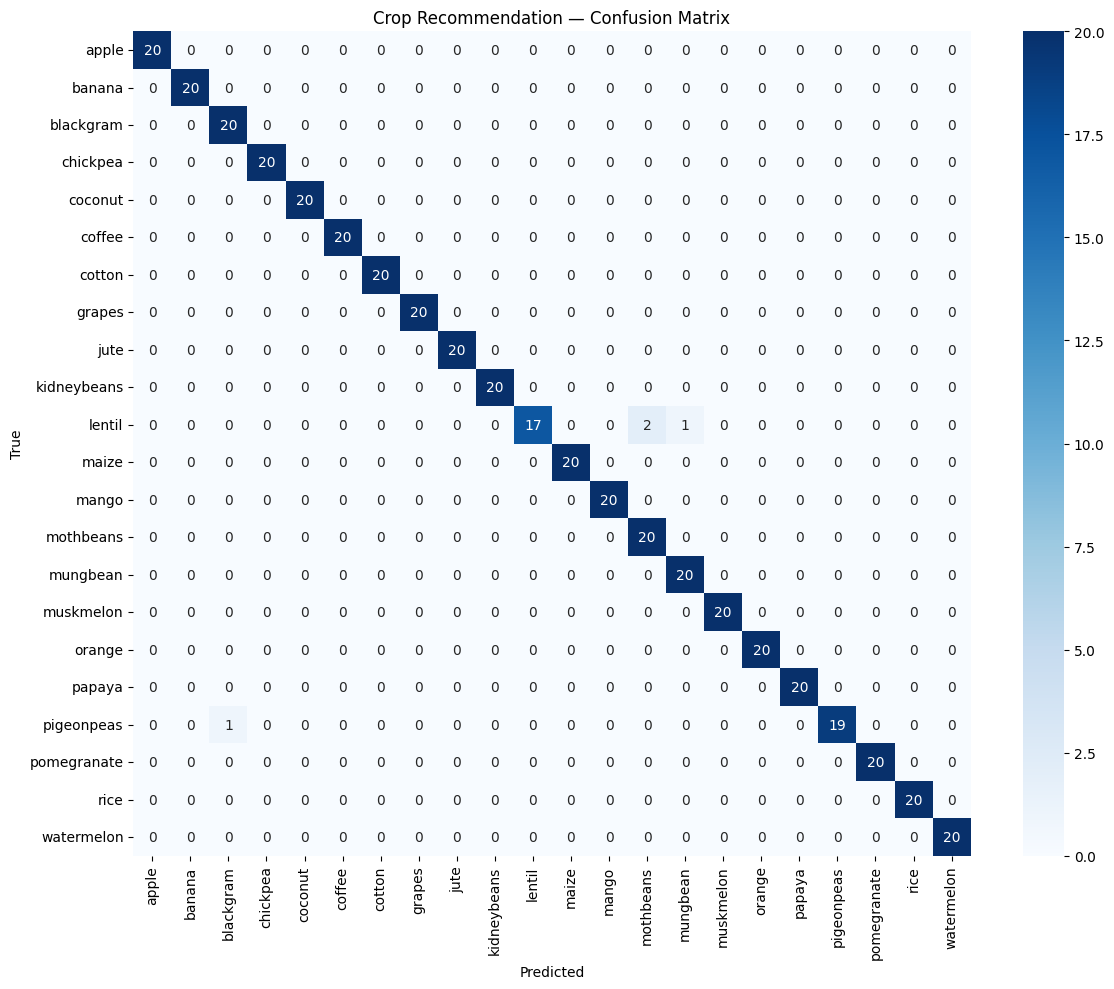

In [16]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Crop Recommendation — Confusion Matrix')
plt.tight_layout()
plt.show()

## 9. Feature Importance (SHAP-ready)

Built-in gain-based importance. For the SHAP explainability deliverable in the project doc, use
`shap.TreeExplainer(model)` on this same fitted model.

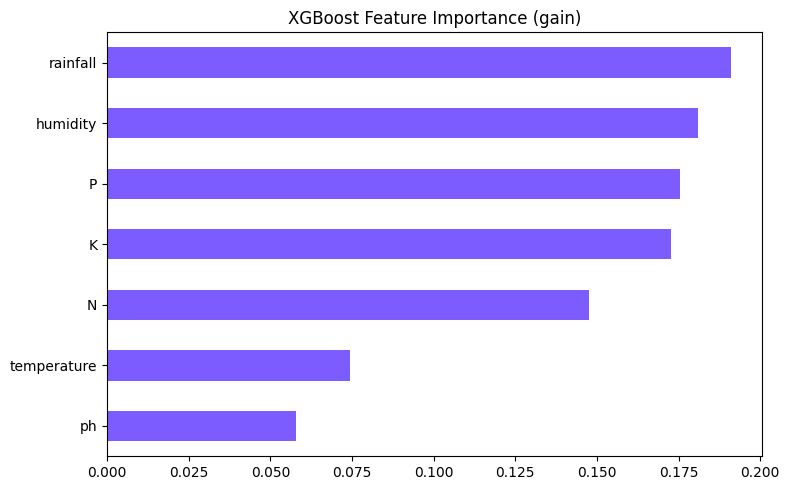

In [17]:
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
importance.plot(kind='barh', figsize=(8, 5), color='#7c5cff')
plt.title('XGBoost Feature Importance (gain)')
plt.tight_layout()
plt.show()

## 10. Save Model Artifacts

Saved into `models/` next to the CNN checkpoint. The FastAPI service loads these at inference time.

In [18]:
model_path = MODELS_DIR / 'crop_xgb.json'
encoder_path = MODELS_DIR / 'crop_label_encoder.joblib'
meta_path = MODELS_DIR / 'crop_model_meta.json'

model.save_model(model_path)
joblib.dump(label_encoder, encoder_path)

meta = {
    'feature_cols': feature_cols,
    'classes': list(label_encoder.classes_),
    'thresholds': THRESHOLDS,
    'ph_bands': {'acidic': '<6.0', 'neutral': '6.0-7.5', 'alkaline': '>7.5'},
}
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2)

print('Saved:')
print(' ', model_path)
print(' ', encoder_path)
print(' ', meta_path)

Saved:
  /kaggle/working/models/crop_xgb.json
  /kaggle/working/models/crop_label_encoder.joblib
  /kaggle/working/models/crop_model_meta.json


## 11. Inference Helper

Single-sample prediction returning the recommended crop, top-3 alternatives, and the deficiency flags —
the shape the recommendation engine / API will consume.

In [19]:
def analyze_soil(N, P, K, temperature, humidity, ph, rainfall, top_k=3):
    row = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]], columns=feature_cols)
    proba = model.predict_proba(row)[0]
    top_idx = np.argsort(proba)[::-1][:top_k]
    return {
        'recommended_crop': label_encoder.classes_[top_idx[0]],
        'top_crops': [
            {'crop': label_encoder.classes_[i], 'confidence': round(float(proba[i]), 4)}
            for i in top_idx
        ],
        'deficiencies': {
            'N': nutrient_status(N, **THRESHOLDS['N']),
            'P': nutrient_status(P, **THRESHOLDS['P']),
            'K': nutrient_status(K, **THRESHOLDS['K']),
            'pH': ph_status(ph),
        },
    }

# Example (run after training):
# analyze_soil(N=90, P=42, K=43, temperature=20.9, humidity=82.0, ph=6.5, rainfall=203.0)

In [20]:
analyze_soil(N=90, P=42, K=43, temperature=20.9, humidity=82.0, ph=6.5, rainfall=203.0)

{'recommended_crop': 'rice',
 'top_crops': [{'crop': 'rice', 'confidence': 0.9987},
  {'crop': 'jute', 'confidence': 0.0004},
  {'crop': 'coffee', 'confidence': 0.0001}],
 'deficiencies': {'N': 'high',
  'P': 'adequate',
  'K': 'adequate',
  'pH': 'neutral'}}